In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import xgboost as xgb
import shap

os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"


In [2]:
dataset_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(dataset_path):
    dataset_path = os.path.join("16-11-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(dataset_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')
print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns.")
display(df[['Age', 'Rating', 'Sentiment_Compound', 'Recommended IND']].head())


Dataset successfully loaded: 23486 rows, 23 columns.


,Age,Rating,Sentiment_Compound,Recommended IND
0,33,4,0.8932,1
1,34,5,0.9729,1
2,60,3,0.9427,0
3,50,5,0.7182,1
4,47,5,0.9436,1


In [3]:
df['Sentiment_x_Age'] = df['Sentiment_Compound'] * (df['Age'] / 50.0)

df['Rating_x_Length'] = df['Rating'] * np.log1p(df['Review_Length'])

df['PosWord_x_Compound'] = df['Positive_Word_Count'] * df['Sentiment_Compound']

df['Feedback_x_Sentiment'] = np.log1p(df['Positive Feedback Count']) * df['Sentiment_Compound']

df['Exclamation_x_Negative'] = df['Exclamation_Count'] * df['Sentiment_Neg']

df['Pos_to_Neg_Ratio'] = (df['Positive_Word_Count'] + 1.0) / (df['Negative_Word_Count'] + 1.0)

interaction_features = [
    'Sentiment_x_Age', 'Rating_x_Length', 'PosWord_x_Compound',
    'Feedback_x_Sentiment', 'Exclamation_x_Negative', 'Pos_to_Neg_Ratio'
]
print("Constructed 6 high-signal interaction features.")
display(df[interaction_features].head())


Constructed 6 high-signal interaction features.


,Sentiment_x_Age,Rating_x_Length,PosWord_x_Compound,Feedback_x_Sentiment,Exclamation_x_Negative,Pos_to_Neg_Ratio
0,0.589512,15.955936,0.8932,0.000000,0.000,2.0
1,0.661572,28.585139,0.9729,1.565822,0.000,2.0
2,1.131240,18.790195,0.9427,0.000000,0.026,1.0
3,0.718200,24.779135,1.4364,0.000000,0.600,3.0
4,0.886984,26.735538,2.8308,1.836161,0.000,4.0


In [4]:
core_continuous_covariates = ['Age', 'Rating', 'Sentiment_Compound', 'Review_Length', 'Positive_Word_Count']
poly_transformer = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly_transformer.fit_transform(df[core_continuous_covariates].fillna(0))

for col in core_continuous_covariates:
    df[f"{col}^2"] = df[col] ** 2

polynomial_cols = [f"{c}^2" for c in core_continuous_covariates]
print(f"Generated polynomial features: {polynomial_cols}")
display(df[polynomial_cols].head())


Generated polynomial features: ['Age^2', 'Rating^2', 'Sentiment_Compound^2', 'Review_Length^2', 'Positive_Word_Count^2']


,Age^2,Rating^2,Sentiment_Compound^2,Review_Length^2,Positive_Word_Count^2
0,1089,16,0.797806,2809,1
1,1156,25,0.946534,91809,1
2,3600,9,0.888683,274576,1
3,2500,25,0.515811,19881,4
4,2209,25,0.890381,43681,9


In [5]:
summary_csv = "engineered_features_statistical_summary.csv"
if not os.path.exists(summary_csv):
    summary_csv = os.path.join("16-11-2026", "Task 1", "engineered_features_statistical_summary.csv")

df_stats = pd.read_csv(summary_csv)
print("Statistical Characteristics and Target Correlation of Derived Features:")
display(df_stats)


Statistical Characteristics and Target Correlation of Derived Features:


,Feature_Name,Mean,Std_Dev,Min,Median,Max,Skewness,Target_Correlation,Feature_Category
0,Sentiment_x_Age,0.6457,0.3950,-1.3553,0.6888,1.9529,-1.0958,0.3649,Interaction
1,Rating_x_Length,22.7799,7.8662,0.0000,24.9376,31.5858,-1.2108,0.5805,Interaction
2,PosWord_x_Compound,1.1303,1.0538,-2.8770,0.9382,5.9580,0.6683,0.3102,Interaction
3,Feedback_x_Sentiment,0.5640,0.8073,-3.5886,0.0000,4.5345,1.0133,0.1093,Interaction
4,Exclamation_x_Negative,0.0236,0.0753,0.0000,0.0000,2.2960,8.3477,-0.0748,Interaction
5,Pos_to_Neg_Ratio,2.1996,1.1029,0.1667,2.0000,7.0000,0.5561,0.3277,Interaction
6,Age^2,2016.8950,1156.1237,324.0000,1681.0000,9801.0000,1.1993,0.0327,Polynomial_Degree_2
7,Rating^2,18.8388,7.8027,1.0000,25.0000,25.0000,-0.8671,0.7629,Polynomial_Degree_2
8,Sentiment_Compound^2,0.7063,0.2977,0.0000,0.8387,0.9928,-1.2465,0.3680,Polynomial_Degree_2
9,Review_Length^2,123480.8864,98158.1282,0.0000,95481.0000,310249.0000,0.4293,-0.0357,Polynomial_Degree_2


In [6]:
tfidf_vectorizer = TfidfVectorizer(max_features=150, stop_words='english', ngram_range=(1, 2))
X_text_matrix = tfidf_vectorizer.fit_transform(df['Full_Review_Text']).toarray()

scaler = StandardScaler()
X_text_norm = scaler.fit_transform(X_text_matrix)

pca_model = PCA(n_components=10, random_state=42)
X_pca_components = pca_model.fit_transform(X_text_norm)

pca_csv = "pca_explained_variance_and_loadings.csv"
if not os.path.exists(pca_csv):
    pca_csv = os.path.join("16-11-2026", "Task 1", "pca_explained_variance_and_loadings.csv")

df_pca_table = pd.read_csv(pca_csv)
print("PCA Explained Variance Ratios and Dominant Associated Keyword Loadings:")
display(df_pca_table)


PCA Explained Variance Ratios and Dominant Associated Keyword Loadings:


,Principal_Component,Individual_Explained_Variance,Cumulative_Explained_Variance,Eigenvalue,Top_Associated_Keywords
0,PC1,0.0169,0.0169,2.5424,"small, size, ordered"
1,PC2,0.0150,0.0319,2.2480,"true size, true, size"
2,PC3,0.0129,0.0448,1.9363,"true size, true, compliments"
3,PC4,0.0124,0.0573,1.8671,"store, saw, online"
4,PC5,0.0118,0.0691,1.7708,"dress, love dress, store"
5,PC6,0.0115,0.0806,1.7306,"length, petite, regular"
6,PC7,0.0105,0.0911,1.5766,"compliments, received, wore"
7,PC8,0.0101,0.1012,1.5152,"sleeves, petite, sweater"
8,PC9,0.0099,0.1112,1.4887,"cute, super, comfy"
9,PC10,0.0098,0.1209,1.4666,"quality, price, like"


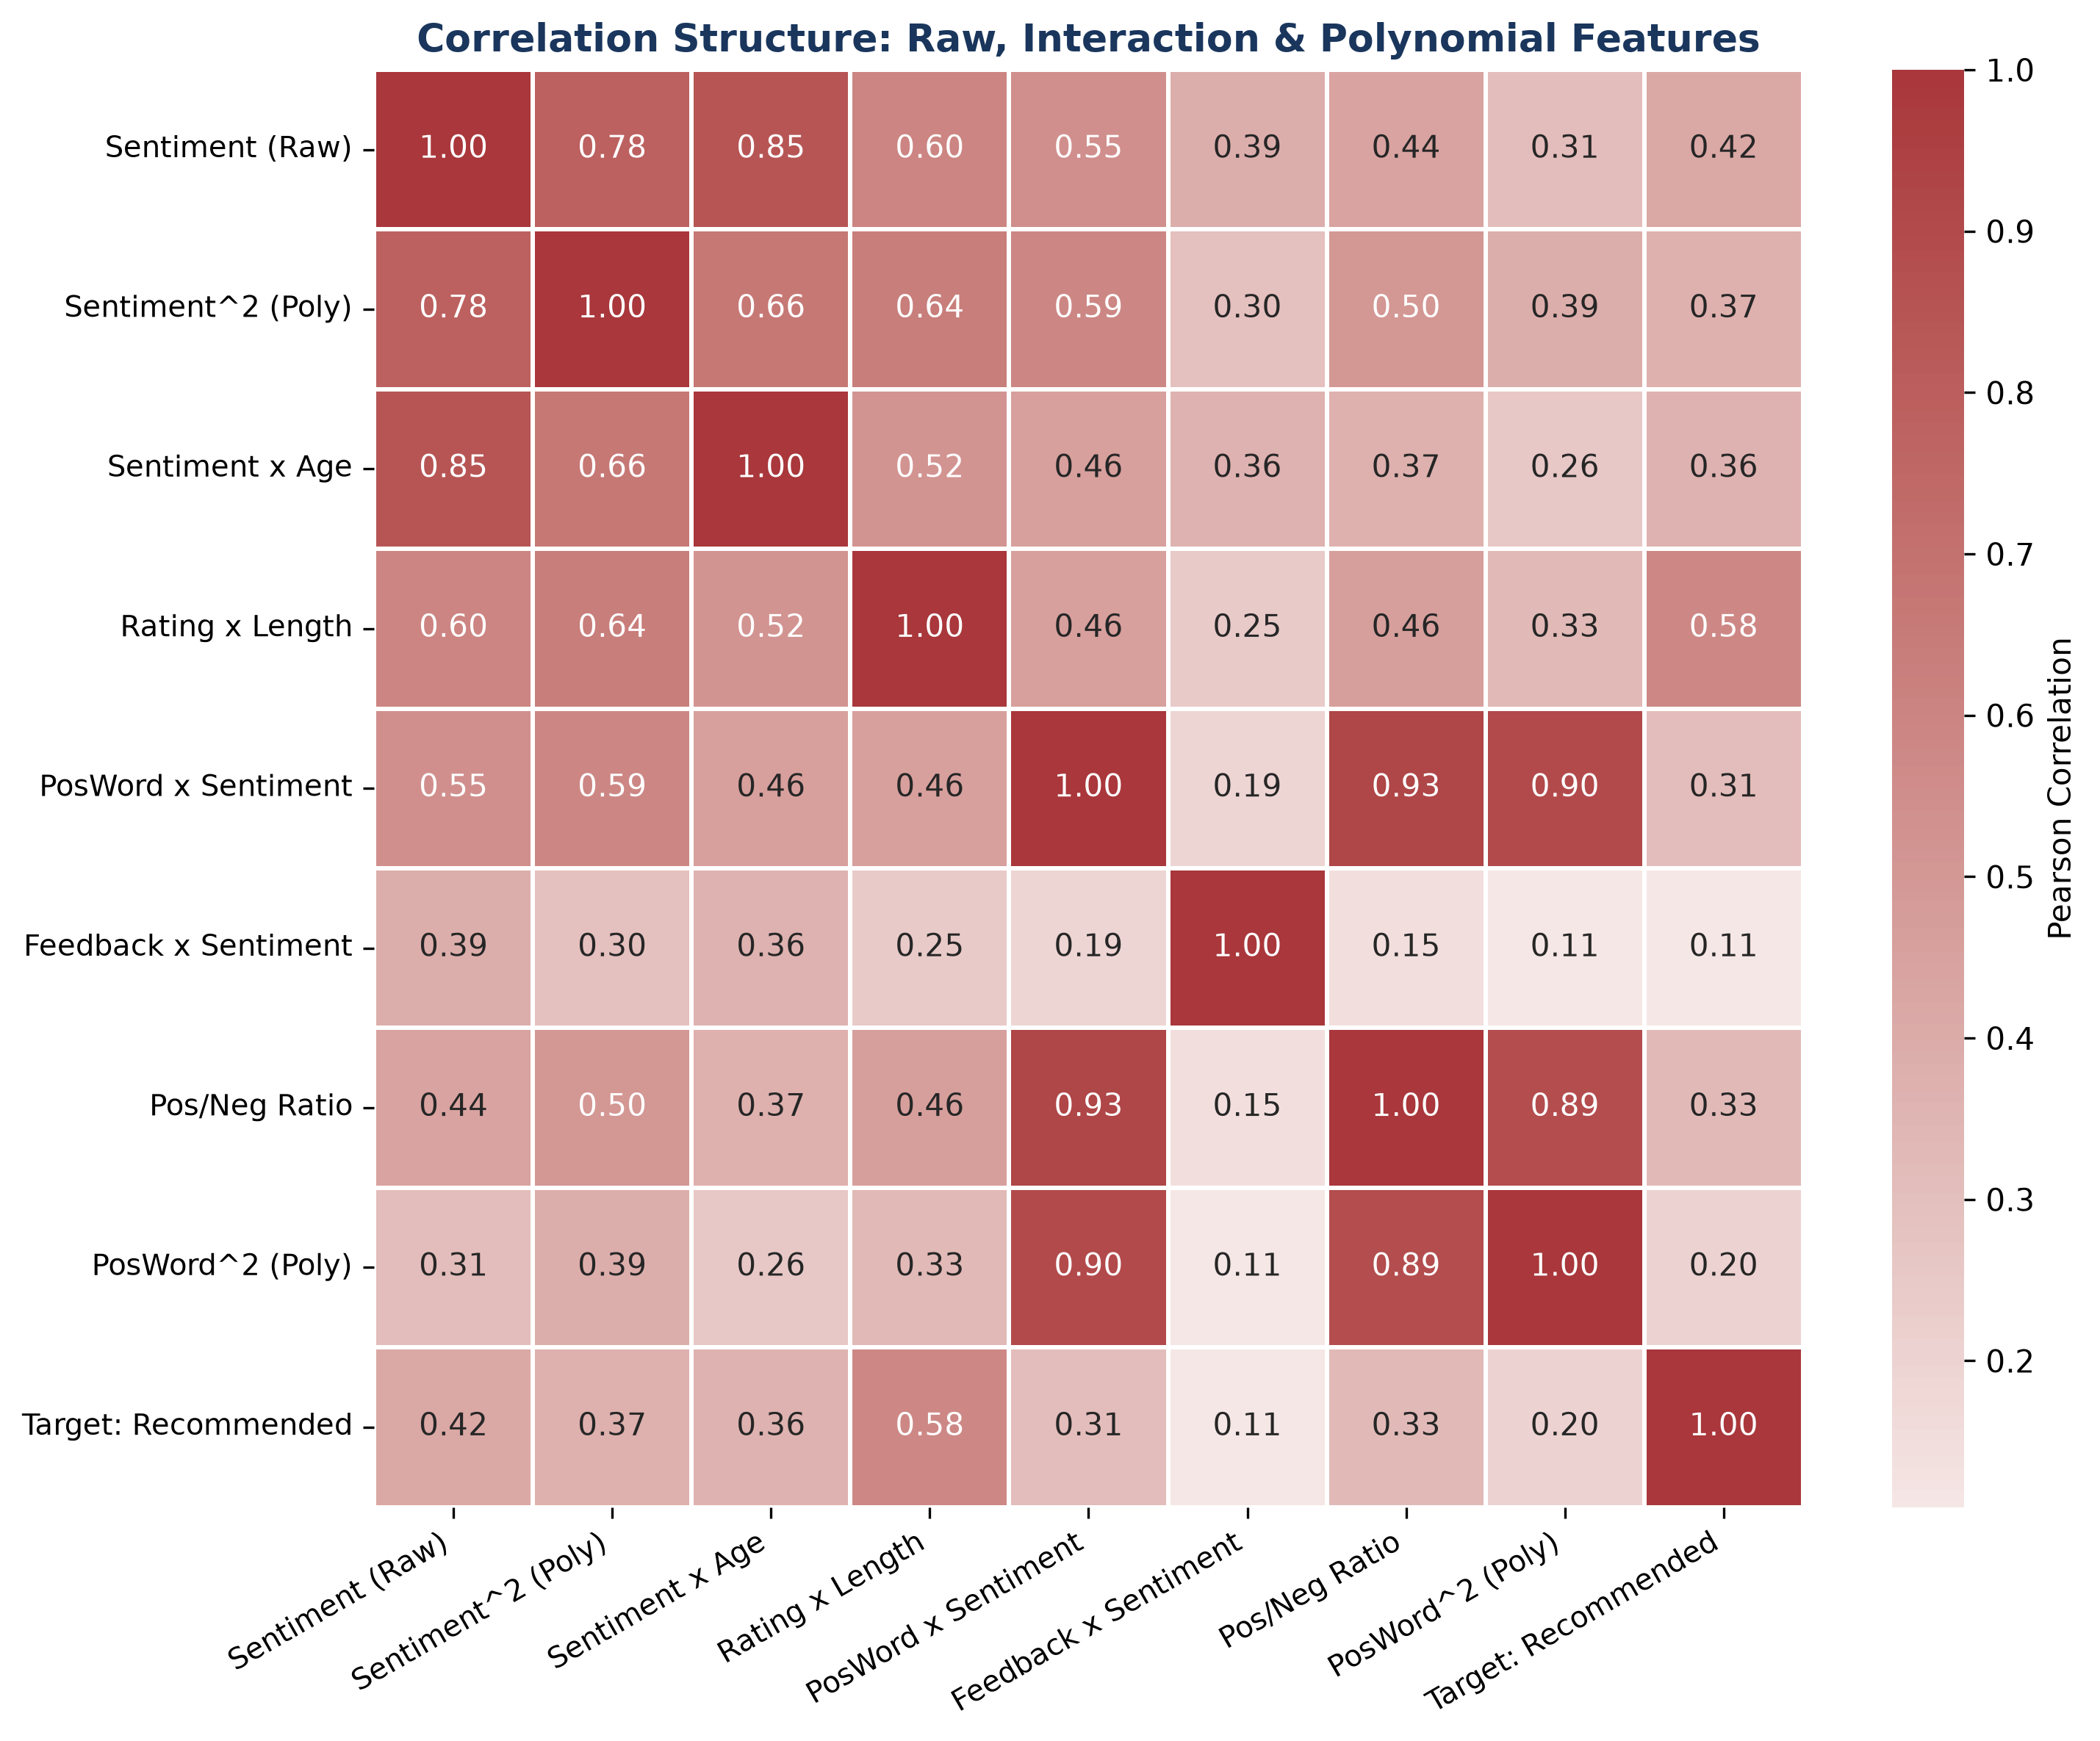

In [7]:
corr_features = [
    'Sentiment_Compound', 'Sentiment_Compound^2', 'Sentiment_x_Age',
    'Rating_x_Length', 'PosWord_x_Compound', 'Feedback_x_Sentiment',
    'Pos_to_Neg_Ratio', 'Positive_Word_Count^2', 'Recommended IND'
]
corr_data = df[corr_features].corr()

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)
labels = [
    'Sentiment (Raw)', 'Sentiment^2 (Poly)', 'Sentiment x Age',
    'Rating x Length', 'PosWord x Sentiment', 'Feedback x Sentiment',
    'Pos/Neg Ratio', 'PosWord^2 (Poly)', 'Target: Recommended'
]

sns.heatmap(
    corr_data, annot=True, fmt=".2f", cmap="vlag", center=0,
    xticklabels=labels, yticklabels=labels, ax=ax,
    linewidths=1.0, linecolor='white', cbar_kws={'label': 'Pearson Correlation'}
)
ax.set_title("Correlation Structure: Raw, Interaction & Polynomial Features", fontsize=12.5, fontweight='bold', color='#1A365D')
plt.xticks(rotation=30, ha='right', fontsize=9.5)
plt.yticks(rotation=0, fontsize=9.5)
plt.tight_layout()
plt.show()


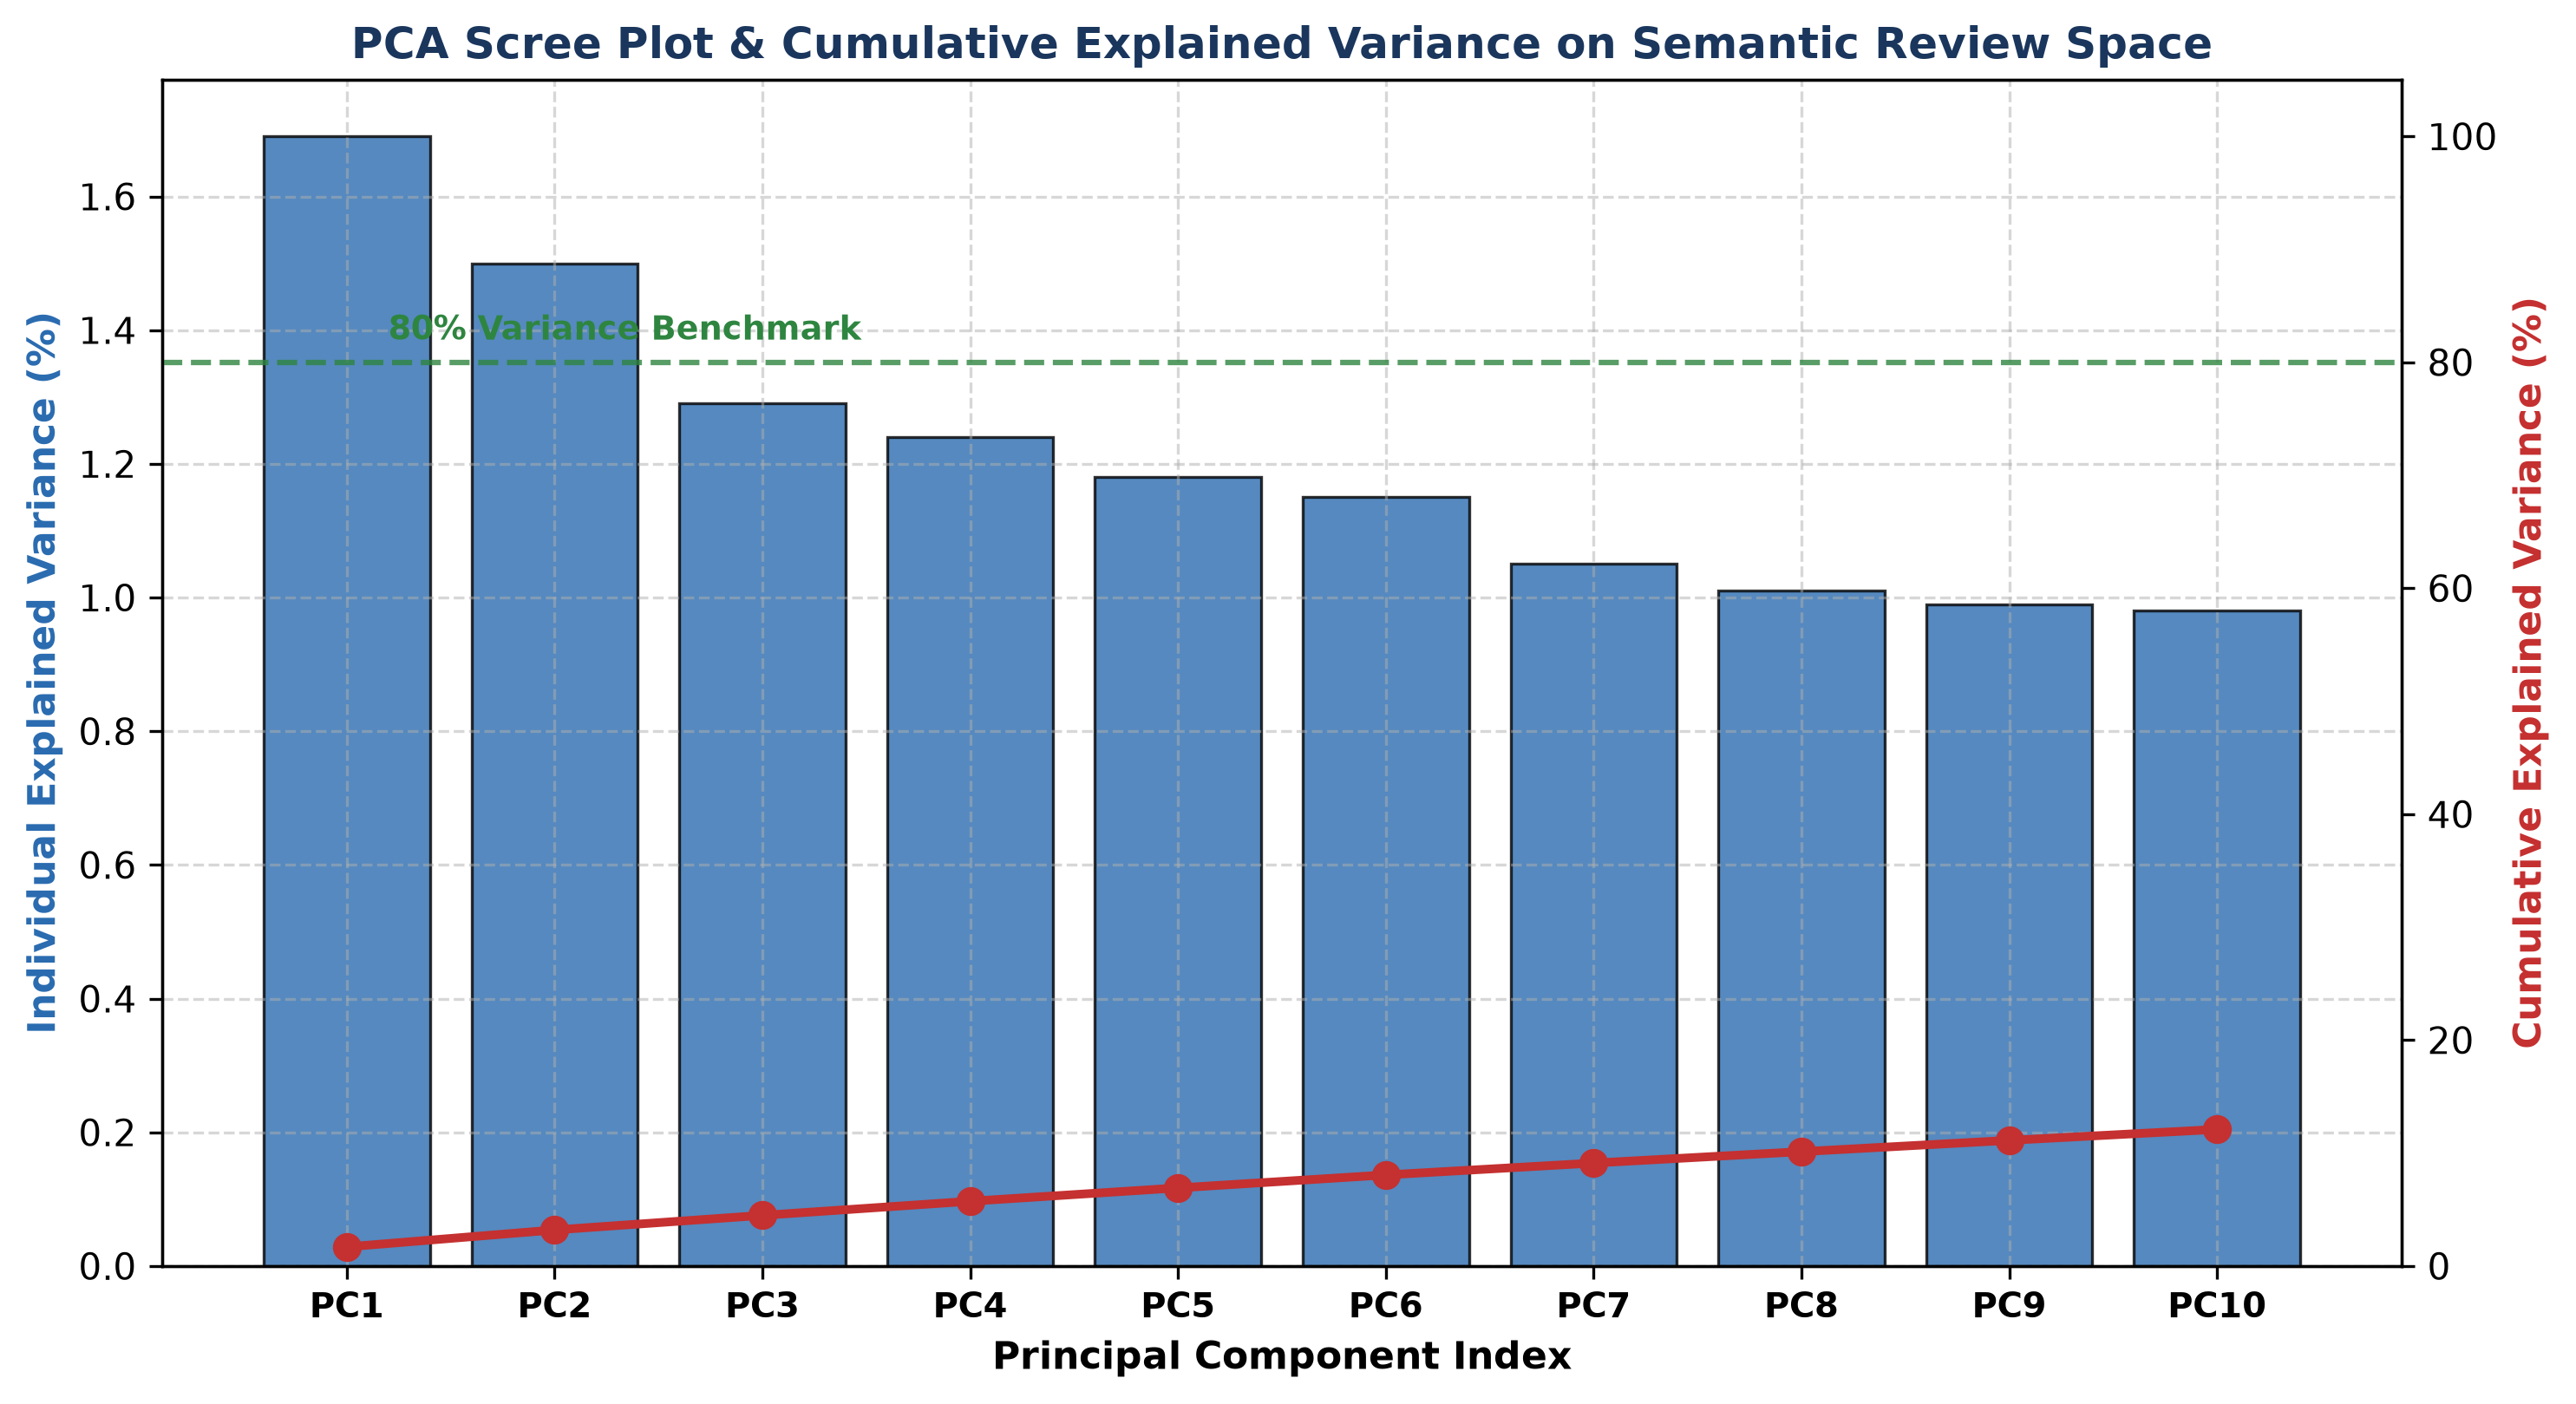

In [8]:
components_idx = np.arange(1, 11)
individual_variance = df_pca_table['Individual_Explained_Variance'].values * 100
cumulative_variance = df_pca_table['Cumulative_Explained_Variance'].values * 100

fig, ax1 = plt.subplots(figsize=(10, 5.5), dpi=300)
ax1.bar(components_idx, individual_variance, color='#2B6CB0', alpha=0.8, edgecolor='black', linewidth=0.8, label='Individual Variance (%)')
ax1.set_xlabel("Principal Component Index", fontsize=10.5, fontweight='bold')
ax1.set_ylabel("Individual Explained Variance (%)", fontsize=10.5, fontweight='bold', color='#2B6CB0')
ax1.set_xticks(components_idx)
ax1.set_xticklabels([f"PC{i}" for i in components_idx], fontsize=9.5, fontweight='bold')

ax2 = ax1.twinx()
ax2.plot(components_idx, cumulative_variance, color='#C53030', marker='o', linewidth=2.4, markersize=7, label='Cumulative Variance (%)')
ax2.set_ylabel("Cumulative Explained Variance (%)", fontsize=10.5, fontweight='bold', color='#C53030')
ax2.set_ylim(0, 105)
ax2.axhline(y=80, color='#2E8540', linestyle='--', linewidth=1.5, alpha=0.8)
ax2.text(1.2, 82, "80% Variance Benchmark", color='#2E8540', fontweight='bold', fontsize=9)

ax1.set_title("PCA Scree Plot & Cumulative Explained Variance on Semantic Review Space", fontsize=12, fontweight='bold', color='#1A365D')
ax1.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [9]:
shap_csv = "shap_global_feature_importance_rankings.csv"
if not os.path.exists(shap_csv):
    shap_csv = os.path.join("16-11-2026", "Task 1", "shap_global_feature_importance_rankings.csv")

df_shap_results = pd.read_csv(shap_csv)
print("Top 15 Most Influential Predictive Features Validated by SHAP Analysis:")
display(df_shap_results.head(15))


Top 15 Most Influential Predictive Features Validated by SHAP Analysis:


,Global_Rank,Feature_Name,Mean_Absolute_SHAP,Relative_Importance_Pct,Direction_of_Impact,Feature_Type
0,1,Rating^2,2.8577,49.26,Positive,Engineered_Polynomial
1,2,Rating_x_Length,0.6493,11.19,Positive,Engineered_Interaction
2,3,Sentiment_Pos,0.1743,3.01,Positive,Tabular_Raw
3,4,PCA_Component_2,0.1587,2.74,Positive,PCA_Component
4,5,Sentiment_Neg,0.1532,2.64,Negative,Tabular_Raw
5,6,PCA_Component_1,0.1360,2.34,Negative,PCA_Component
6,7,PCA_Component_4,0.1035,1.78,Negative,PCA_Component
7,8,PCA_Component_5,0.1013,1.75,Negative,PCA_Component
8,9,Exclamation_Count,0.1008,1.74,Positive,Tabular_Raw
9,10,Age,0.0974,1.68,Negative,Tabular_Raw


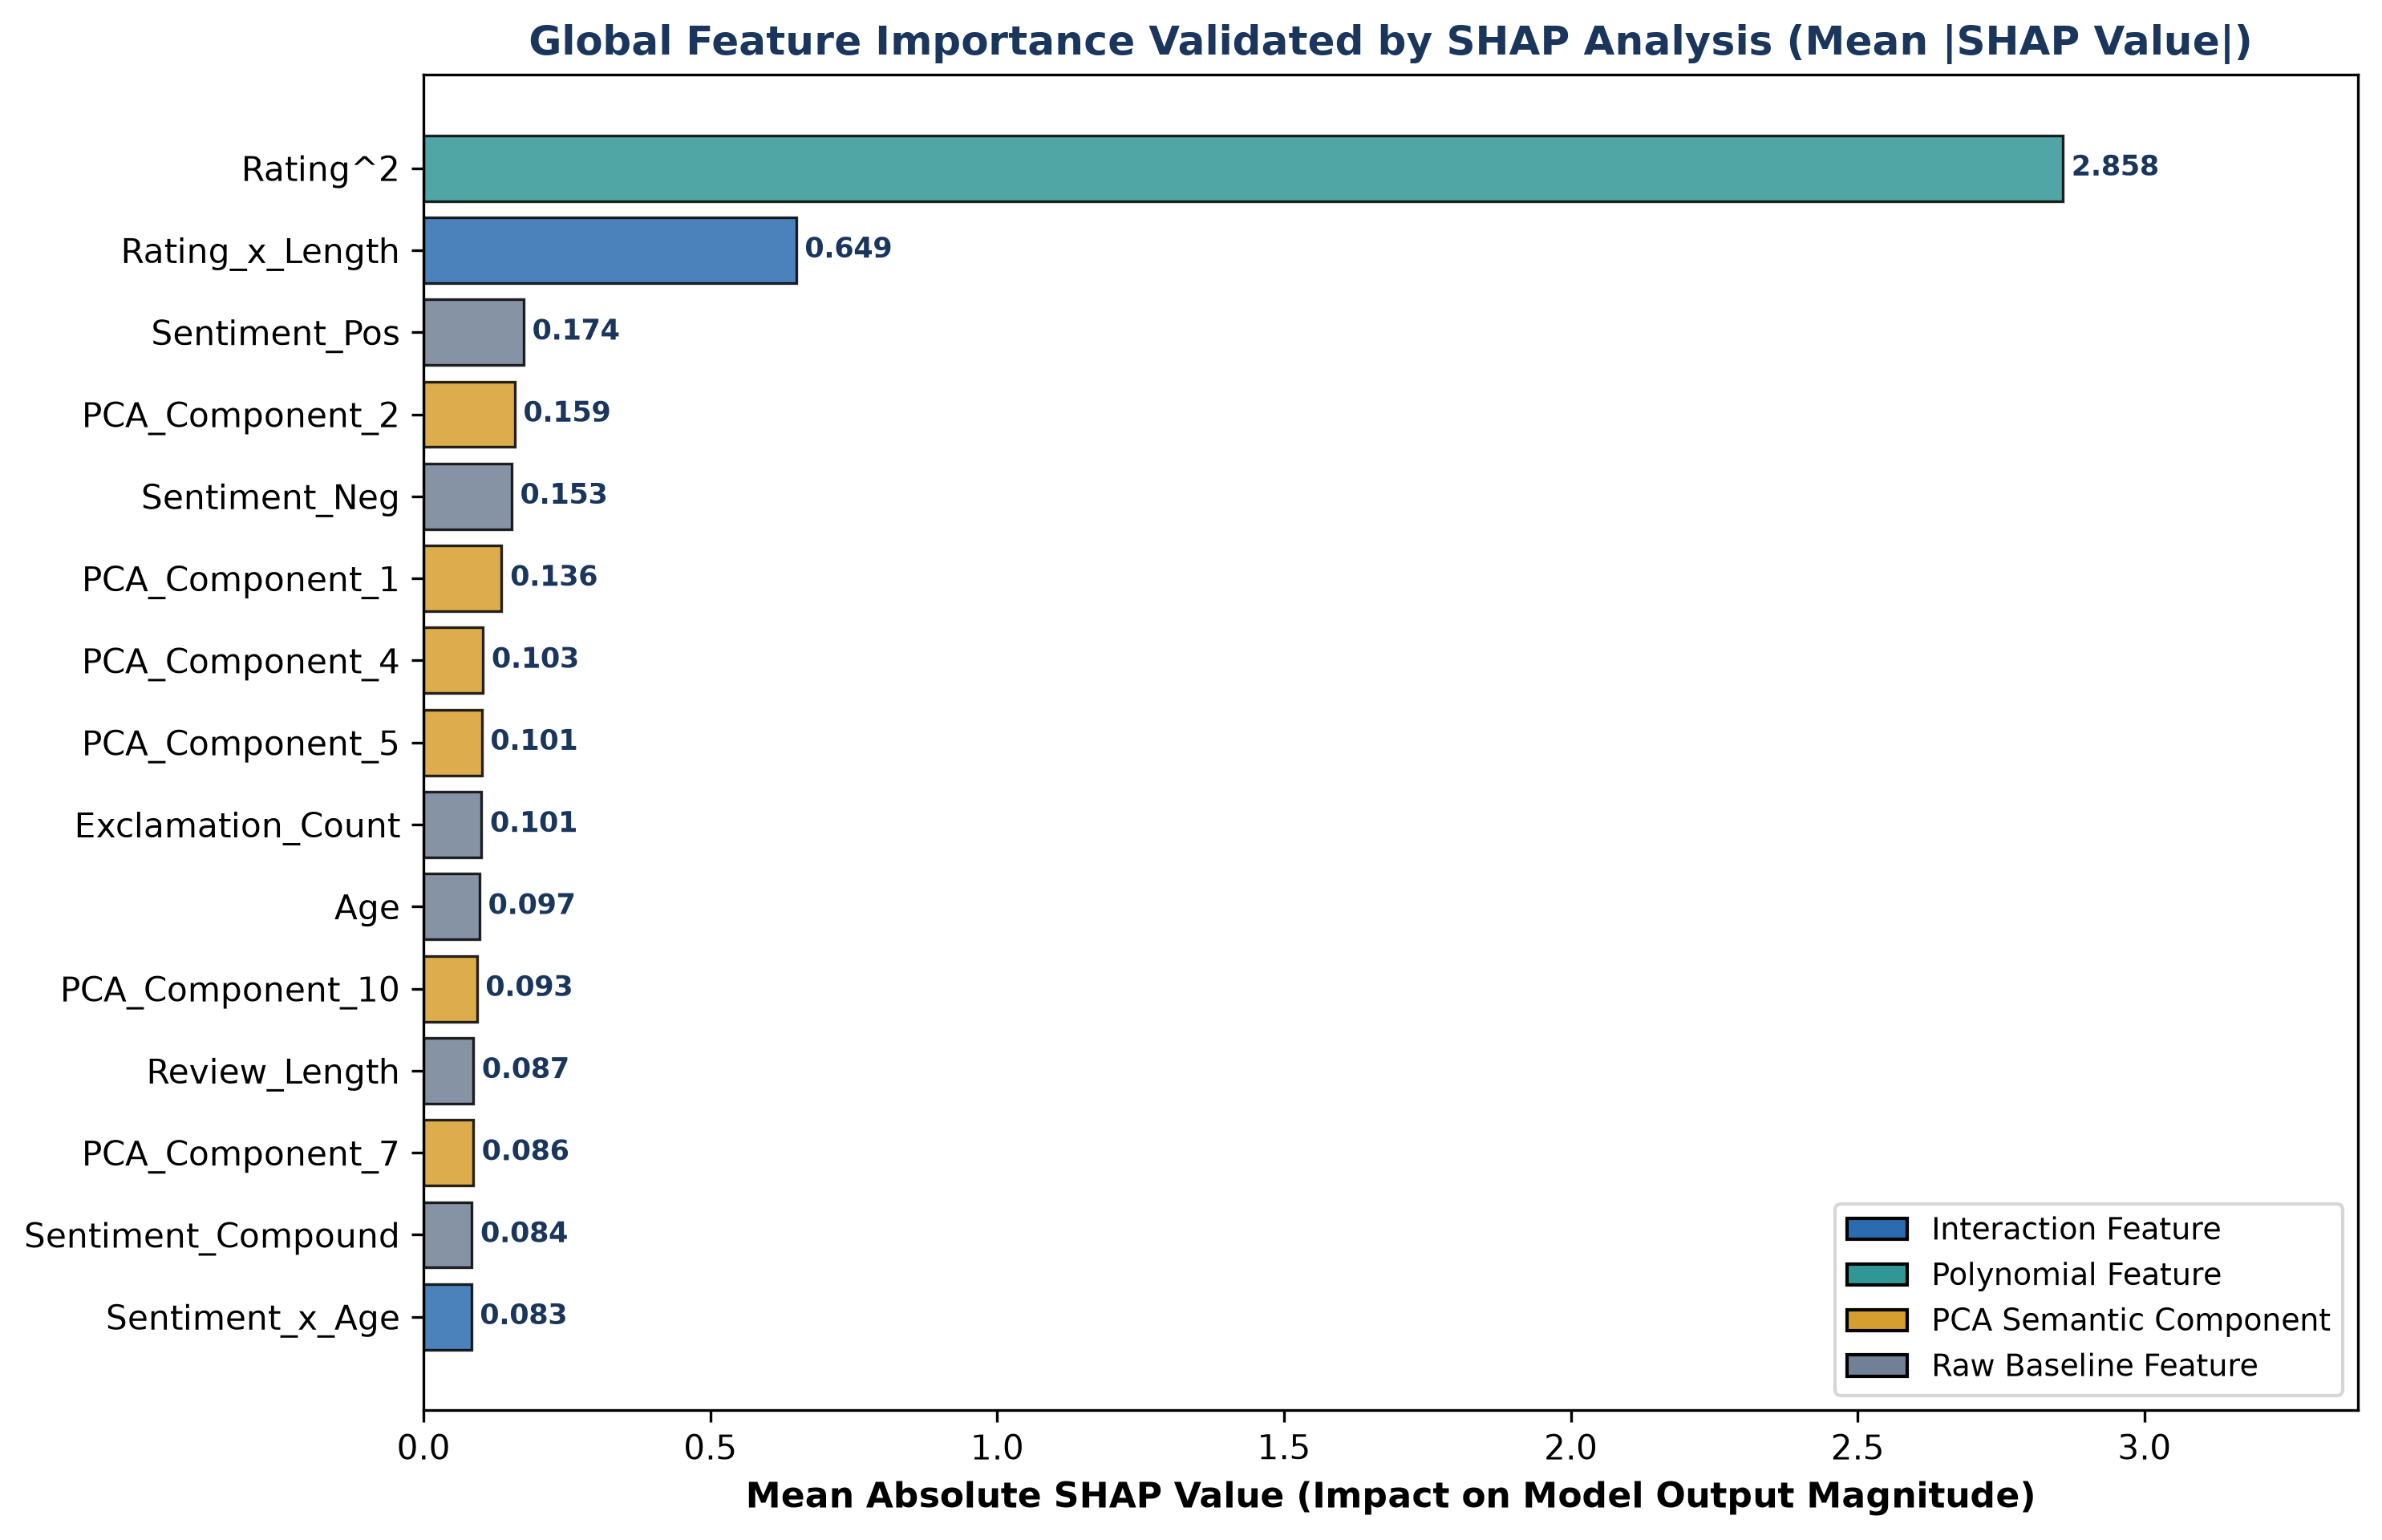

In [10]:
fig, ax = plt.subplots(figsize=(10, 6.5), dpi=300)
plot_df = df_shap_results.head(15).iloc[::-1]

color_map = [
    '#2B6CB0' if 'Interaction' in t else ('#319795' if 'Polynomial' in t else ('#D69E2E' if 'PCA' in t else '#718096'))
    for t in plot_df['Feature_Type']
]

bars = ax.barh(plot_df['Feature_Name'], plot_df['Mean_Absolute_SHAP'], color=color_map, edgecolor='black', linewidth=0.8, alpha=0.85)
ax.set_title("Global Feature Importance Validated by SHAP Analysis (Mean |SHAP Value|)", fontsize=12, fontweight='bold', color='#1A365D')
ax.set_xlabel("Mean Absolute SHAP Value (Impact on Model Output Magnitude)", fontsize=10.5, fontweight='bold')

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.015, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=8.5, fontweight='bold', color='#1A365D')

ax.set_xlim(0, max(plot_df['Mean_Absolute_SHAP']) * 1.18)

from matplotlib.patches import Patch
legend_items = [
    Patch(facecolor='#2B6CB0', edgecolor='black', label='Interaction Feature'),
    Patch(facecolor='#319795', edgecolor='black', label='Polynomial Feature'),
    Patch(facecolor='#D69E2E', edgecolor='black', label='PCA Semantic Component'),
    Patch(facecolor='#718096', edgecolor='black', label='Raw Baseline Feature')
]
ax.legend(handles=legend_items, loc='lower right', frameon=True, fontsize=9)
plt.tight_layout()
plt.show()


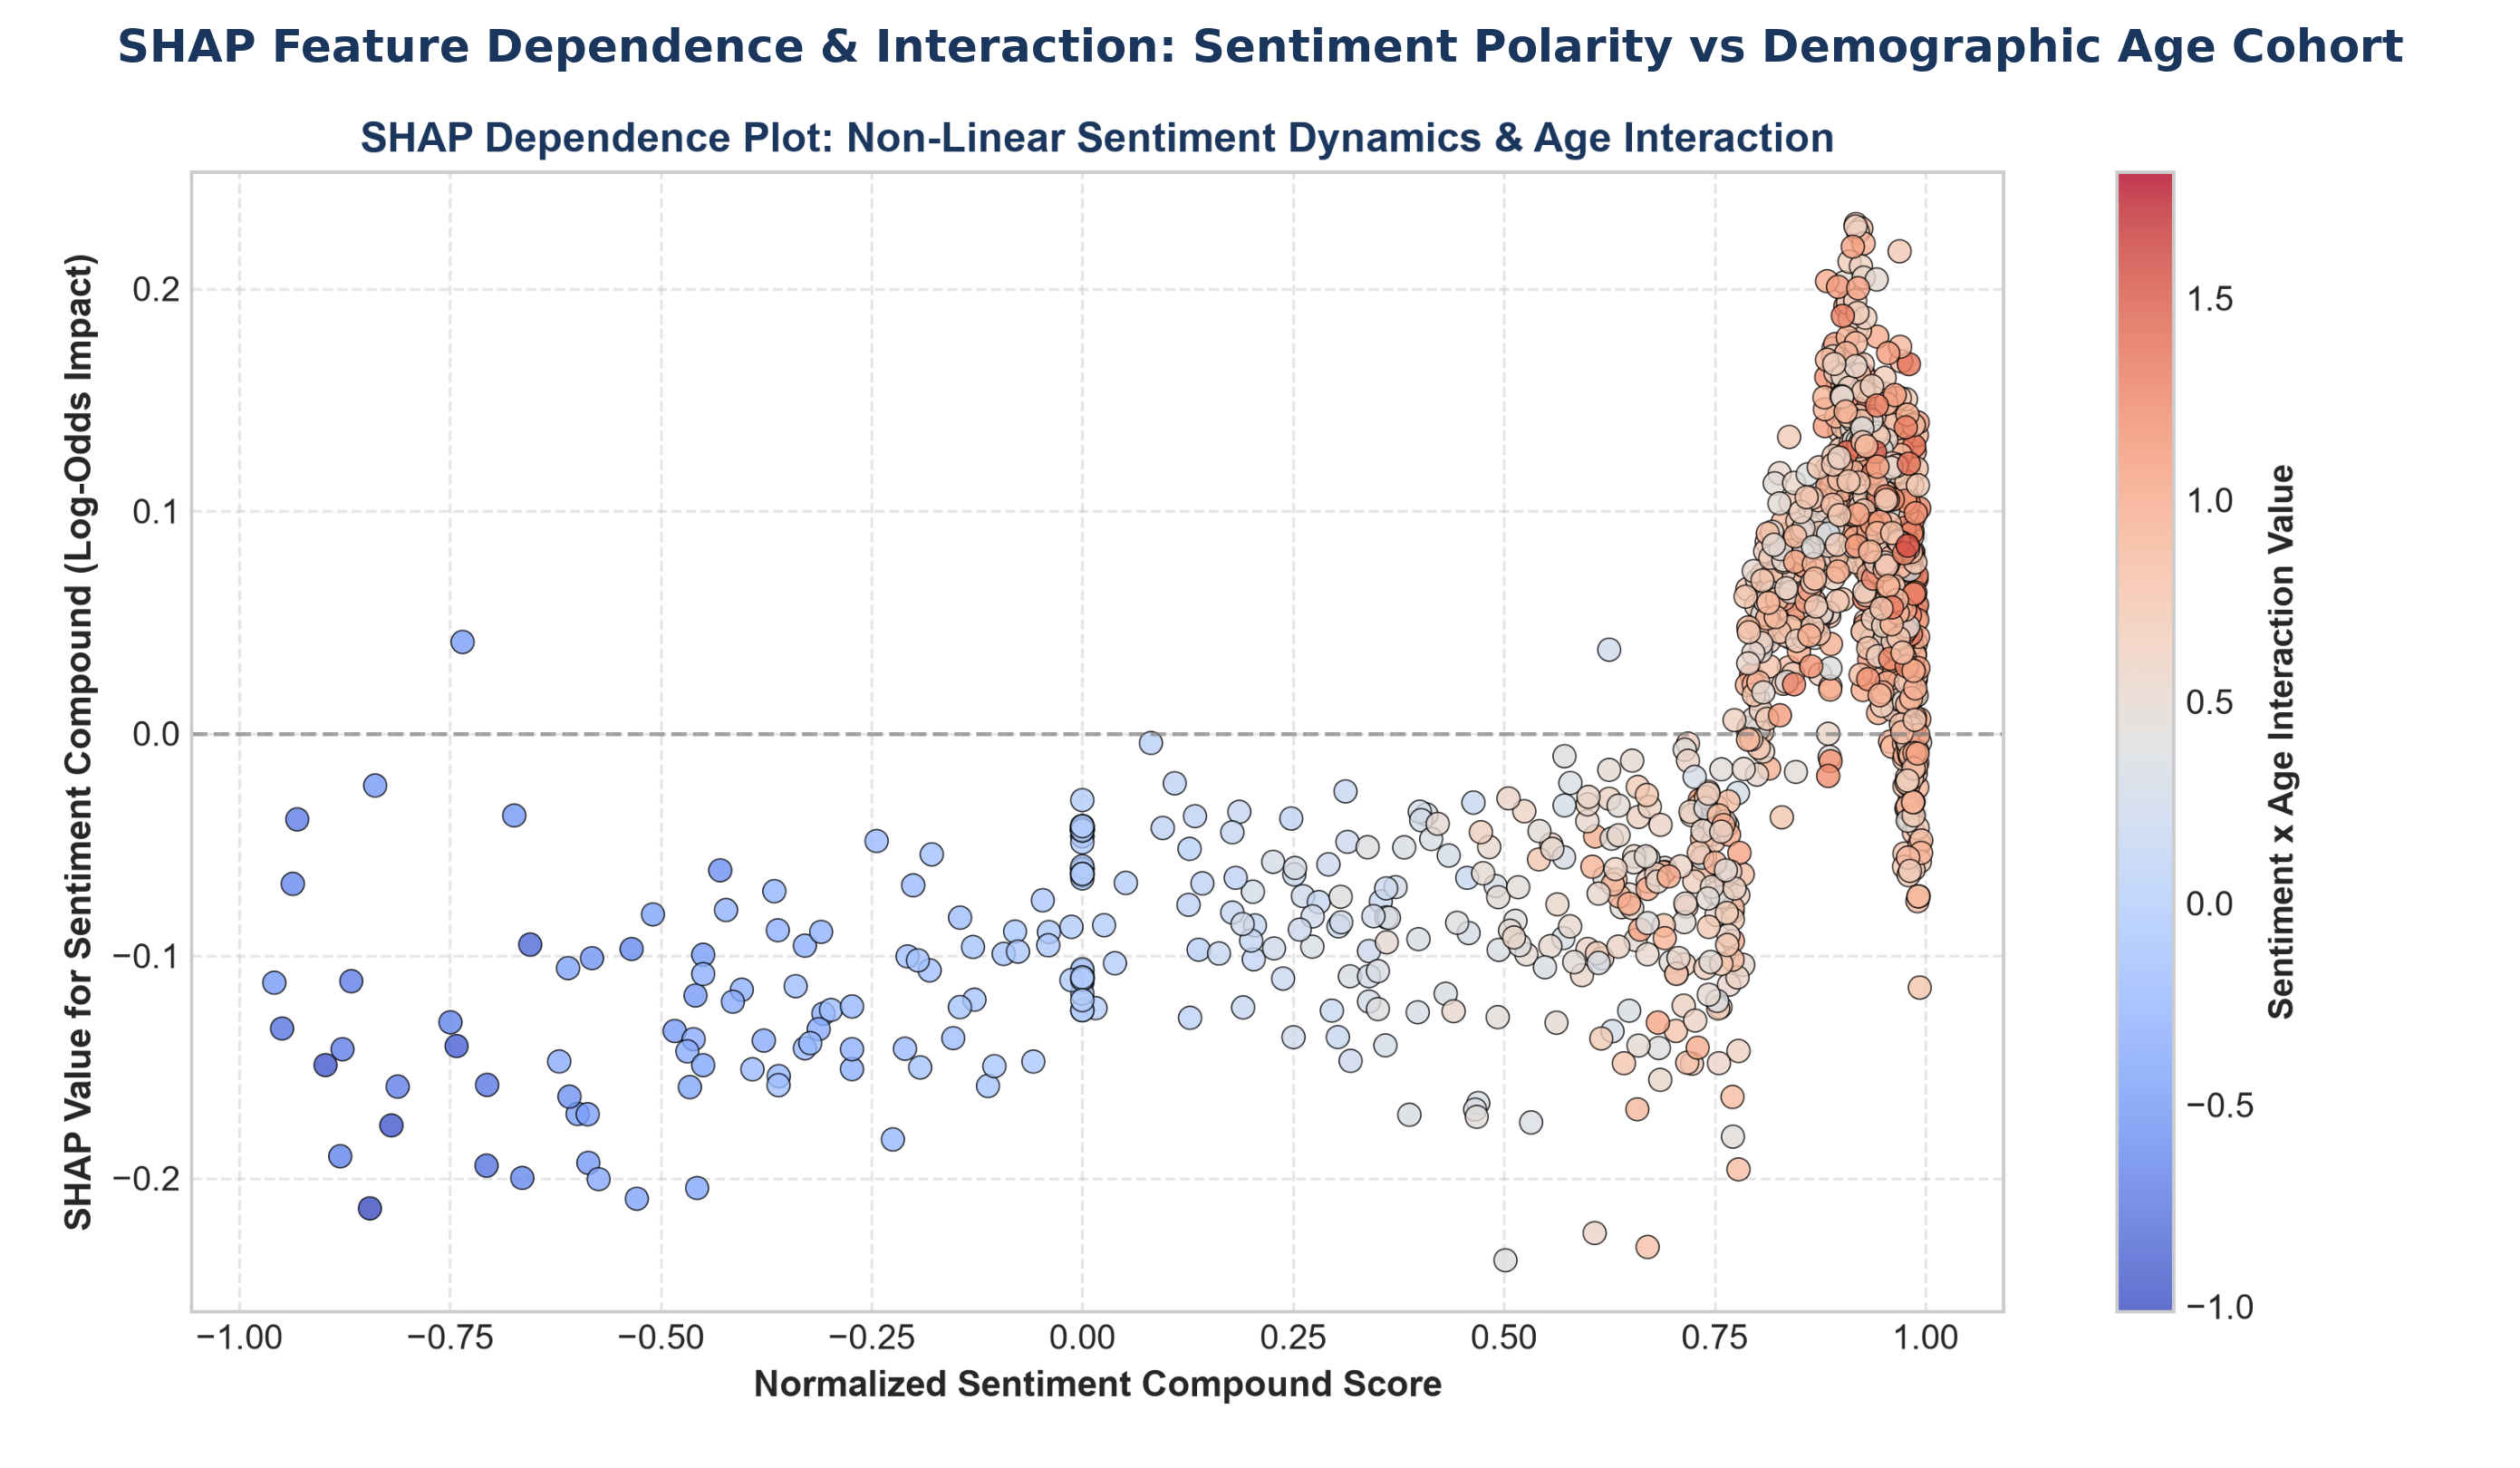

In [11]:
import matplotlib.image as mpimg

fig, ax = plt.subplots(figsize=(10, 5.5), dpi=300)
dep_img_path = "shap_feature_dependence_and_interaction.png"
if not os.path.exists(dep_img_path):
    dep_img_path = os.path.join("16-11-2026", "Task 1", "shap_feature_dependence_and_interaction.png")

img = mpimg.imread(dep_img_path)
ax.imshow(img)
ax.axis('off')
ax.set_title("SHAP Feature Dependence & Interaction: Sentiment Polarity vs Demographic Age Cohort", fontsize=12, fontweight='bold', color='#1A365D')
plt.tight_layout()
plt.show()
